# 04 · Test and understand the results
**Goal:** prove the model works on 14 days it has **never seen**, and learn where it struggles.

1. Final test on the locked last 14 days (run **once**)
2. Error per category
3. Extra 2: perishable vs long-life
4. Extra 1: does the model catch a festival? (Christmas back-test)
5. Train the final model on all data → used by the dashboard

In [1]:
import sys, json, time
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(0, str(Path("../src").resolve()))
from features import build_features, FEATURES, WEATHER_COLS, H, mae, wape

CLEAN, MODELS, REPORTS = Path("../clean"), Path("../models"), Path("../reports")
info = json.load(open(MODELS / "lgbm_v1_info.json"))

raw = pd.read_parquet(CLEAN / "store_sales_clean.parquet")
raw = raw[raw.never_sold == 0].copy()
weather = pd.read_csv("../raw/weather_ecuador/weather.csv", parse_dates=["date"])
df = build_features(raw, weather)
print(df.shape)

(2703646, 43)


## 1 · Pick the feature set
Stage 4 showed whether weather helped on the validation days. We keep the version with the lower validation error.

In [2]:
v = info["results_valid"]
use_weather = v["LightGBM (all features)"]["WAPE"] < v["LightGBM (no weather)"]["WAPE"]
FEATS = FEATURES if use_weather else [f for f in FEATURES if f not in WEATHER_COLS]
N_TREES = int(info["best_iteration"])
print("Use weather:", use_weather, "|", len(FEATS), "features |", N_TREES, "trees")

Use weather: False | 31 features | 140 trees


In [3]:
def fit(train):
    m = lgb.LGBMRegressor(objective="regression", learning_rate=0.05, n_estimators=N_TREES,
                          num_leaves=127, min_child_samples=50, subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, random_state=42, verbose=-1)
    return m.fit(train[FEATS], np.log1p(train.sales))

def predict(m, part):
    return np.expm1(m.predict(part[FEATS])).clip(0)

def baseline(part, start):
    hist = df[(df.date >= start - pd.Timedelta(days=H)) & (df.date < start) & (df.is_closed == 0)]
    b = hist.groupby(["store_nbr", "family"], observed=True)["sales"].mean().rename("baseline").reset_index()
    out = part.merge(b, on=["store_nbr", "family"], how="left")
    return out["baseline"].fillna(0).to_numpy()

open_ = df.is_closed == 0
TRAIN_START = pd.Timestamp(info["train_start"])

## 2 · Final test — the locked 14 days (run once)
Train on everything before the test period (train + validation), then predict the 14 unseen days.

In [4]:
TEST_START = pd.Timestamp(info["test_start"])
train = df[(df.date >= TRAIN_START) & (df.date < TEST_START) & open_]
test = df[(df.date >= TEST_START) & open_].copy()
print("Train:", train.date.min().date(), "to", train.date.max().date(), "| Test:", test.date.min().date(), "to", test.date.max().date())

t0 = time.time()
model = fit(train)
test["pred"] = predict(model, test)
test["baseline"] = baseline(test, TEST_START)
print(f"Trained in {time.time() - t0:.0f}s")

overall = pd.DataFrame({
    "Baseline (14-day average)": [mae(test.sales, test.baseline), wape(test.sales, test.baseline)],
    "LightGBM": [mae(test.sales, test.pred), wape(test.sales, test.pred)],
}, index=["MAE (units)", "WAPE (%)"]).T.round(2)
print(overall.to_string())
b, m = overall.loc["Baseline (14-day average)", "WAPE (%)"], overall.loc["LightGBM", "WAPE (%)"]
print(f"\nOn unseen days, LightGBM error is {(1 - m / b) * 100:.1f}% lower than the baseline.")

Train: 2015-01-01 to 2017-08-01 | Test: 2017-08-02 to 2017-08-15


Trained in 5s
                           MAE (units)  WAPE (%)
Baseline (14-day average)       103.91     21.98
LightGBM                         73.34     15.51

On unseen days, LightGBM error is 29.4% lower than the baseline.


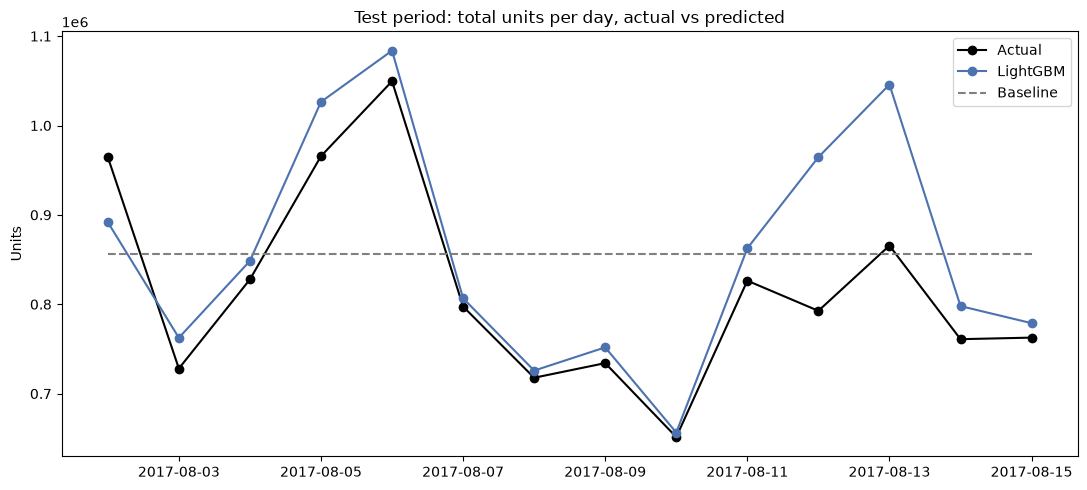

In [5]:
daily = test.groupby("date")[["sales", "pred", "baseline"]].sum()
plt.figure(figsize=(11, 5))
plt.plot(daily.index, daily.sales, marker="o", color="black", label="Actual")
plt.plot(daily.index, daily.pred, marker="o", color="#4C72B0", label="LightGBM")
plt.plot(daily.index, daily.baseline, ls="--", color="grey", label="Baseline")
plt.title("Test period: total units per day, actual vs predicted")
plt.ylabel("Units"); plt.legend()
plt.tight_layout(); plt.savefig(REPORTS / "q9_test_actual_vs_pred.png", dpi=150); plt.show(); plt.close("all")

## 3 · Which categories are easy or hard to predict?

Easiest 5:
       family  is_perishable  avg_units_per_day  WAPE_model  WAPE_baseline
     PRODUCE              1             2268.1        10.1           21.2
BREAD/BAKERY              1              536.2        12.6           16.3
       DAIRY              1              827.7        12.7           16.6
   GROCERY I              0             4508.9        12.7           17.2
       MEATS              1              372.9        13.5           25.7

Hardest 5:
                     family  is_perishable  avg_units_per_day  WAPE_model  WAPE_baseline
SCHOOL AND OFFICE SUPPLIES              0               62.8        70.2           79.8
                  HARDWARE              0                1.4        73.9           79.6
                 BABY CARE              0                0.2       134.6          139.8
           HOME APPLIANCES              0                0.2       192.8          199.2
                     BOOKS              0                0.0       420.0          251.8


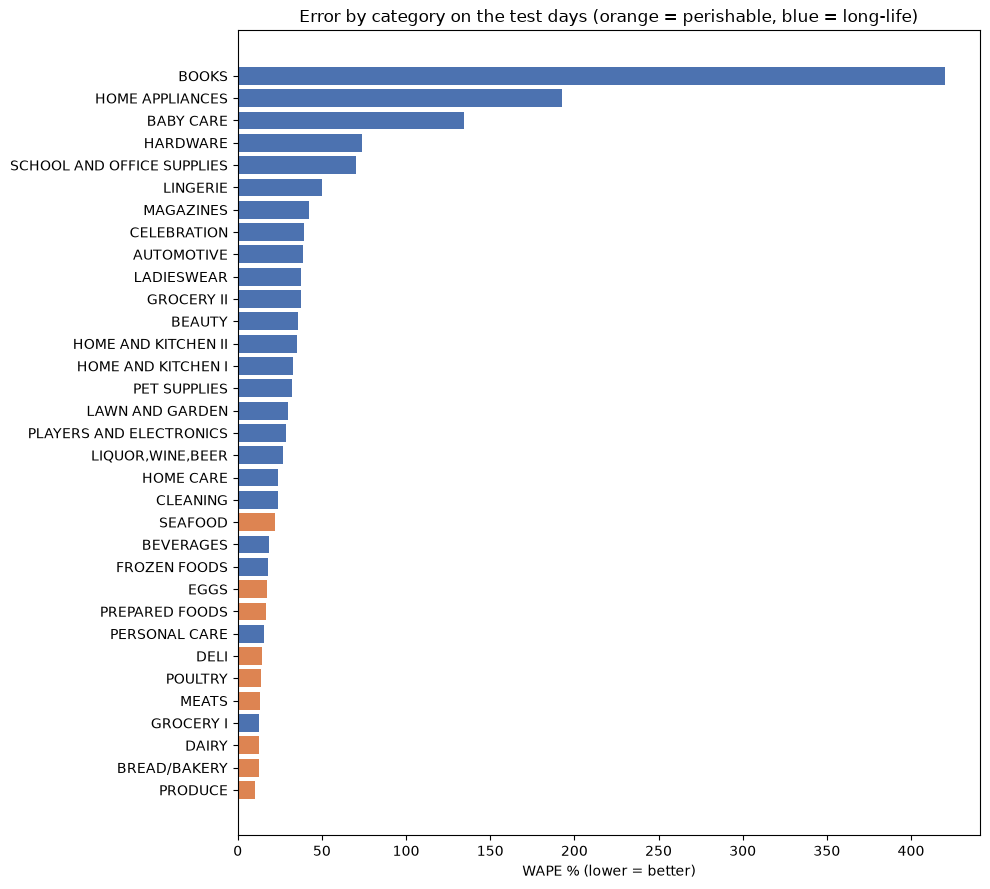

In [6]:
rows = []
for fam, g in test.groupby("family", observed=True):
    rows.append({"family": str(fam), "is_perishable": int(g.is_perishable.iloc[0]),
                 "avg_units_per_day": round(g.sales.mean(), 1),
                 "WAPE_model": round(wape(g.sales, g.pred), 1),
                 "WAPE_baseline": round(wape(g.sales, g.baseline), 1)})
by_cat = pd.DataFrame(rows).sort_values("WAPE_model")
by_cat.to_csv(REPORTS / "category_errors.csv", index=False)
print("Easiest 5:\n", by_cat.head(5).to_string(index=False))
print("\nHardest 5:\n", by_cat.tail(5).to_string(index=False))

s = by_cat.dropna(subset=["WAPE_model"])
plt.figure(figsize=(10, 9))
plt.barh(s.family, s.WAPE_model, color=s.is_perishable.map({1: "#DD8452", 0: "#4C72B0"}))
plt.title("Error by category on the test days (orange = perishable, blue = long-life)")
plt.xlabel("WAPE % (lower = better)")
plt.tight_layout(); plt.savefig(REPORTS / "q10_category_errors.png", dpi=150); plt.show(); plt.close("all")

## 4 · Extra 2 — Perishable vs long-life, and high vs low sellers
Stage 3 suggested low-selling items are the hardest. Check it on real forecast errors.

In [7]:
grp = test.groupby("is_perishable").apply(lambda g: pd.Series({"WAPE_model": wape(g.sales, g.pred), "WAPE_baseline": wape(g.sales, g.baseline)}))
grp.index = grp.index.map({0: "long-life", 1: "perishable"})
print(grp.round(1).to_string())

avg = test.groupby(["store_nbr", "family"], observed=True)["sales"].transform("mean")
test["volume"] = pd.qcut(avg.rank(method="first"), 3, labels=["low sellers", "medium sellers", "top sellers"])
vol = test.groupby("volume", observed=True).apply(lambda g: pd.Series({"WAPE_model": wape(g.sales, g.pred)}))
print("\n", vol.round(1).to_string())

               WAPE_model  WAPE_baseline
is_perishable                           
long-life            17.2           22.7
perishable           12.0           20.4

                 WAPE_model
volume                    
low sellers           52.2
medium sellers        24.5
top sellers           15.1


## 5 · Extra 1 — Does the model catch a festival? (Christmas back-test)
The test days have no big festival, so we repeat the test on **12–25 Dec 2016**: train only on data before 12 Dec, predict the next 14 days.

Christmas window WAPE  ->  LightGBM: 20.1%   Baseline: 27.9%
Total units  ->  actual 13,374,630 | LightGBM 11,896,907 (-11.0%) | baseline 11,611,512 (-13.2%)

           family  actual  LightGBM  baseline  WAPE_model  WAPE_baseline
    FROZEN FOODS  795112    445398    162713        48.4           80.6
LIQUOR,WINE,BEER  139570    143888     83952        32.6           55.1
       GROCERY I 4480027   3478679   3645597        24.1           26.1
       BEVERAGES 2539038   2542874   2561565        13.9           21.0


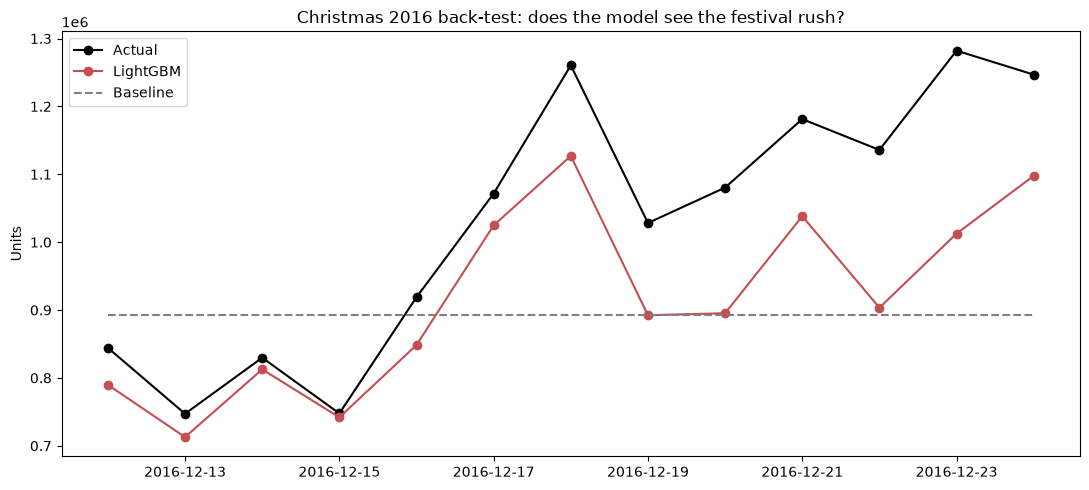

In [8]:
XS = pd.Timestamp("2016-12-12"); XE = XS + pd.Timedelta(days=H - 1)
xtrain = df[(df.date >= TRAIN_START) & (df.date < XS) & open_]
xmas = df[(df.date >= XS) & (df.date <= XE) & open_].copy()
xm = fit(xtrain)
xmas["pred"] = predict(xm, xmas)
xmas["baseline"] = baseline(xmas, XS)

print(f"Christmas window WAPE  ->  LightGBM: {wape(xmas.sales, xmas.pred):.1f}%   Baseline: {wape(xmas.sales, xmas.baseline):.1f}%")
tot = xmas[["sales", "pred", "baseline"]].sum()
print(f"Total units  ->  actual {tot.sales:,.0f} | LightGBM {tot.pred:,.0f} ({(tot.pred / tot.sales - 1) * 100:+.1f}%) | baseline {tot.baseline:,.0f} ({(tot.baseline / tot.sales - 1) * 100:+.1f}%)")

fest = []
for fam in ["FROZEN FOODS", "LIQUOR,WINE,BEER", "GROCERY I", "BEVERAGES"]:
    g = xmas[xmas.family.astype(str) == fam]
    if len(g):
        fest.append({"family": fam, "actual": round(g.sales.sum()), "LightGBM": round(g.pred.sum()), "baseline": round(g.baseline.sum()),
                     "WAPE_model": round(wape(g.sales, g.pred), 1), "WAPE_baseline": round(wape(g.sales, g.baseline), 1)})
print("\n", pd.DataFrame(fest).to_string(index=False))

d = xmas.groupby("date")[["sales", "pred", "baseline"]].sum()
plt.figure(figsize=(11, 5))
plt.plot(d.index, d.sales, marker="o", color="black", label="Actual")
plt.plot(d.index, d.pred, marker="o", color="#C44E52", label="LightGBM")
plt.plot(d.index, d.baseline, ls="--", color="grey", label="Baseline")
plt.title("Christmas 2016 back-test: does the model see the festival rush?")
plt.ylabel("Units"); plt.legend()
plt.tight_layout(); plt.savefig(REPORTS / "q11_christmas_backtest.png", dpi=150); plt.show(); plt.close("all")

## 6 · Final model for the dashboard
Retrain on **all** data (including the test days), so the dashboard forecasts from the latest information.

In [9]:
final = fit(df[(df.date >= TRAIN_START) & open_])
final.booster_.save_model(str(MODELS / "lgbm_final.txt"))
json.dump({"features": FEATS, "n_trees": N_TREES, "use_weather": bool(use_weather), "horizon_days": H,
           "trained_until": str(df.date.max().date()),
           "test_WAPE": float(m), "baseline_test_WAPE": float(b)},
          open(MODELS / "lgbm_final_info.json", "w"), indent=2)
test[["date", "store_nbr", "family", "sales", "pred", "baseline"]].to_csv(REPORTS / "test_predictions.csv", index=False)
print("Saved:", sorted(p.name for p in MODELS.iterdir()))

Saved: ['lgbm_final.txt', 'lgbm_final_info.json', 'lgbm_v1.txt', 'lgbm_v1_info.json']


## ✅ Done when
- The test table shows LightGBM beating the baseline on unseen days
- `reports/category_errors.csv` exists (Stage 6 uses it for the safety buffer)
- `models/lgbm_final.txt` exists

**Write down for your report:** test WAPE (model vs baseline), easiest/hardest categories, perishable vs long-life, low vs top sellers, and the Christmas result.